# 12장 두 캡슐로 이루어진 위계 (실습)

캡슐 두 개를 쌓는다. 위 캡슐은 먹이의 깊이를 추론하고, 그 감각 예측이 아래 캡슐의 사전이 된다. 아래 캡슐은 11장의 캡슐(버전 0.6)로, 수온으로 자기 깊이를 추론하고 행동한다. 환경은 Hydar 의 감각 셋(수온, 압력, 빛)과 따로 움직이는 먹이를 함께 가진다.

1. 다중 감각 환경: 수온, 압력, 빛, 먹이
2. 캡슐 클래스를 감각 사상에 대해 일반화한다
3. 먹이를 따라가는 Hydar
4. 위계 없이 고정 사전만 쓰면
5. 위 캡슐의 사전 정밀도

실패 조건은 위 캡슐이 자기 사전을 지나치게 믿는 경우다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz, inv

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 10.0
t = np.arange(0, T + dt / 2, dt)
N = t.size

def derivativeD(p): return np.eye(p + 1, k=1)

def temporalC(p, s2):
    q = np.arange(p + 1); r = np.zeros(1 + 2 * p)
    r[2 * q] = np.cumprod(1 - 2 * q) / (2 * s2)**q
    S = np.empty((0, p + 1))
    for i in range(p + 1):
        S = np.vstack([S, r[q + i]]); r = -r
    return S

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print(f"시간 점 {N} 개 (10 초)")

시간 점 2001 개 (10 초)


## 1. 다중 감각 환경

Hydar 의 깊이 x 는 행동으로 바뀐다(x′ = u). 감각은 셋이다.

- 수온: g_temp(x) = 25 − 16/(1 + e^(5 − x/5)), 약층이 있는 비선형
- 압력: g_pres(x) = (101326 + 980x)/101326, 수면을 1 로 둔 상대 압력, 선형
- 빛: g_light(x) = e^(−3x/100), 탁한 물에서의 비어-람베르트 감쇠, 비선형

먹이는 따로 움직인다. x_food′ = sin(t/1.8) 로 출렁이고, Hydar 는 먹이의 깊이를 그대로 본다(y_food = x_food). 두 과정은 서로 영향을 주지 않는다. 이 장은 수온과 먹이만 쓰고, 압력과 빛은 13장에서 쓴다.

In [2]:
SENSORS = {
    "temp":  (lambda x: 25 - 16 / (1 + np.exp(5 - x / 5)),
              lambda x: -16 / 5 * np.exp(5 - x / 5) / (1 + np.exp(5 - x / 5))**2),
    "pres":  (lambda x: (101326 + 980 * x) / 101326, lambda x: 980 / 101326 + 0 * x),
    "light": (lambda x: np.exp(-3 * x / 100),          lambda x: -3 / 100 * np.exp(-3 * x / 100)),
    "food":  (lambda x: x,                               lambda x: 1.0 + 0 * x),
}


class HydarFoodEnv:
    """Hydar(깊이, 감각 셋)와 먹이(깊이)의 생성 과정. Gym 형식 reset/step."""

    def __init__(self, t, p=1, noise="none", s2=0.1, food_speed=1.0, seed=42):
        self.t, self.dt, self.p, self.food_speed = t, t[1] - t[0], p, food_speed
        np.random.seed(seed)
        n = makeNoise(np.eye(5) * s2, 1 / 2000, t) if noise == "smooth" else np.zeros((5, t.size))
        self.w_x, self.w_f, self.z = n[0], n[1], {"temp": n[2], "pres": n[3] * 1e-3, "food": n[4]}

    def _gen(self, name, x, xd):
        g, dg = SENSORS[name]
        y = np.zeros((self.p + 1, 1))
        y[0] = g(x) + self.z.get(name, np.zeros(self.t.size))[self.i]
        if self.p >= 1:
            y[1] = dg(x) * xd                                       # 정확한 일반화 감각 (1 차까지)
        return y

    def reset(self, x_init, x_food):
        self.i, self.x, self.xf = 0, x_init, x_food
        return {k: self._gen(k, self.x, 0.0) for k in ["temp", "pres", "light"]} | {"food": self._gen("food", self.xf, 0.0)}

    def step(self, u):
        self.i += 1
        xd = u + self.w_x[self.i]
        fd = self.food_speed * np.sin(self.food_speed * self.t[self.i] / 1.8) + self.w_f[self.i]
        self.x += self.dt * xd
        self.xf += self.dt * fd
        obs = {k: self._gen(k, self.x, xd) for k in ["temp", "pres", "light"]}
        obs["food"] = self._gen("food", self.xf, fd)
        return obs

for d in [0, 15, 25, 40]:
    print(f"깊이 {d:2d} cm   수온 {SENSORS['temp'][0](d):6.2f} °C   압력 {SENSORS['pres'][0](d):.4f}   빛 {SENSORS['light'][0](d):.3f}")

깊이  0 cm   수온  24.89 °C   압력 1.0000   빛 1.000
깊이 15 cm   수온  23.09 °C   압력 1.1451   빛 0.638
깊이 25 cm   수온  17.00 °C   압력 1.2418   빛 0.472
깊이 40 cm   수온   9.76 °C   압력 1.3869   빛 0.301


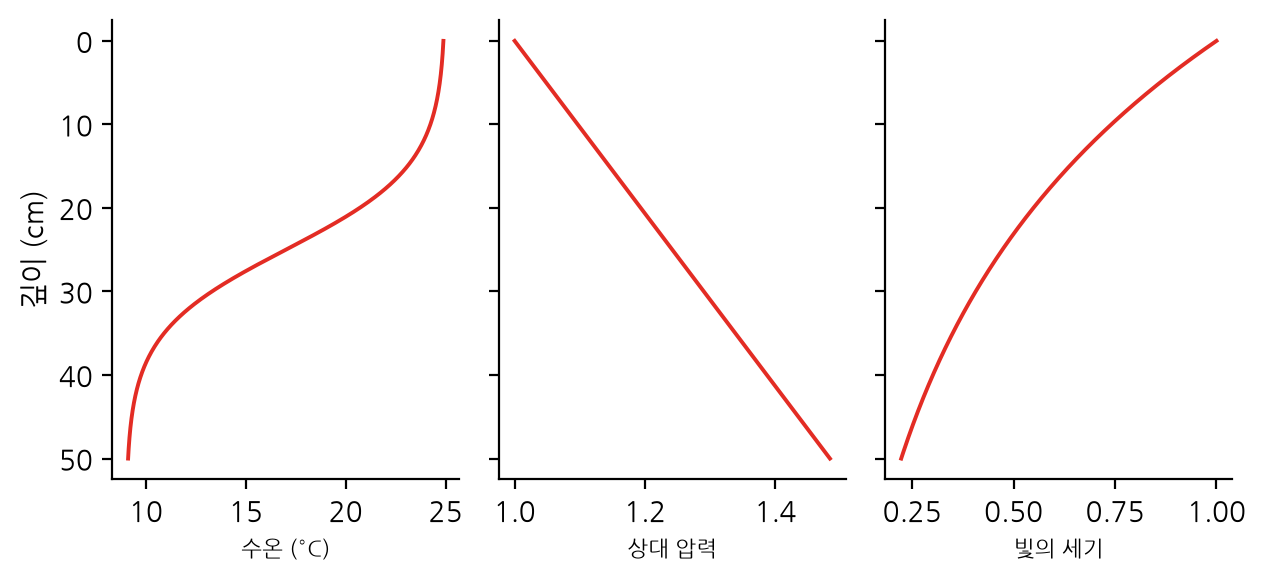

In [3]:
xs = np.linspace(0, 50, 501)
fig, ax = plt.subplots(1, 3, sharey=True, figsize=(6.4, 3.0))
for a_, (name, lab) in zip(ax, [("temp", "수온 (°C)"), ("pres", "상대 압력"), ("light", "빛의 세기")]):
    a_.plot(SENSORS[name][0](xs), xs, color="#E32C24", lw=1.4)
    a_.set_xlabel(lab, fontsize=8)
ax[0].invert_yaxis(); ax[0].set_ylabel("깊이 (cm)")
fig.tight_layout(); plt.show()

## 2. 감각 사상에 대해 일반화한 캡슐

11장의 캡슐(버전 0.6)에서 감각 사상 g 와 그 도함수를 인자로 받게 바꾼다. 위 캡슐은 먹이 감각(g = μ), 아래 캡슐은 수온 감각(g = 시그모이드)을 쓴다. 사전은 매 걸음 바깥에서 일반화 벡터로 넘겨받는다. 전방 모델은 원본처럼 부호 모델이다.

In [4]:
class ai_capsule:
    """감각 사상을 인자로 받는 캡슐 (버전 0.6 일반화). 사전 η̃ 는 매 걸음 넘겨받는다."""

    def __init__(self, sensor, x0, p, s2_x, s2_y, s2_v, a_x, a_v, a_u, fwd_sign=-1.0, s2=1 / 64):
        self.g, self.dg = SENSORS[sensor]
        self.p, self.a_x, self.a_v, self.a_u, self.fwd_sign = p, a_x, a_v, a_u, fwd_sign
        self.I, self.D = np.eye(p + 1), derivativeD(p)
        self.e0 = self.I[:, :1]
        self.mu_x, self.mu_v, self.u = self.e0 * x0, self.e0 * x0, 0.0
        S = temporalC(p, s2)
        self.Pi_x, self.Pi_y, self.Pi_v = (inv(np.kron(S, s)) for s in (s2_x, s2_y, s2_v))

    def predict_y(self):
        """이 캡슐의 감각 예측 g̃(μ̃x): 위 캡슐이면 아래 캡슐의 사전이 된다."""
        g1 = self.dg(self.mu_x[0, 0])
        return self.e0 * self.g(self.mu_x[0, 0]) + (1 - self.e0) * g1 * self.mu_x

    def ai_step(self, eta, y, act=False):
        mx, mv = self.mu_x, self.mu_v
        g1 = self.dg(mx[0, 0])
        eps_x = self.D @ mx - (-mx + mv)                             # f = −μx + μv
        eps_y = y - self.predict_y()
        eps_v = mv - eta
        dF_x = (self.D + self.I).T @ self.Pi_x @ eps_x - g1 * self.Pi_y @ eps_y
        dF_v = -self.Pi_x @ eps_x + self.Pi_v @ eps_v
        self.mu_x = mx + dt * (self.D @ mx - self.a_x * dF_x)
        self.mu_v = mv + dt * (self.D @ mv - self.a_v * dF_v)
        if act:
            fwd = self.fwd_sign * np.ones((self.p + 1, 1))           # 부호 모델
            self.u += dt * -self.a_u * (fwd.T @ self.Pi_y @ eps_y).item()
        return self.u

print("ai_capsule 준비 완료")

ai_capsule 준비 완료


## 3. 먹이를 따라가는 Hydar

Hydar 는 깊이 25 에서, 먹이는 15 에서 출발한다. 위 캡슐의 사전은 「먹이는 16 cm 에 있다」다. 원본의 설정: 아래 캡슐 분산 모두 0.1, αx = 3, αv = 1, αu = 5, 위 캡슐 σx² = σy² = 0.1, σv² = 1, 학습률 1, p = 1, 잡음 없음. 처음 0.5 초는 지각만 한다.

매 걸음 위 캡슐이 먼저 먹이 감각으로 한 걸음 추론하고, 그 감각 예측 g̃(μ̃x(2)) 가 아래 캡슐의 사전 η̃(1) 이 된다.

In [5]:
def run_hier(prior_top=16.0, s2_v_top=1.0, s2_y_top=0.1, hierarchy=True, fixed_prior=16.0, food_speed=1.0,
             noise="none", t_act=0.5, T_=T):
    tt = np.arange(0, T_ + dt / 2, dt)
    env = HydarFoodEnv(tt, p=1, noise=noise, food_speed=food_speed)
    obs = env.reset(25.0, 15.0)
    top = ai_capsule("food", prior_top, 1, 0.1, s2_y_top, s2_v_top, 1, 1, 0)
    bot = ai_capsule("temp", prior_top if hierarchy else fixed_prior, 1, 0.1, 0.1, 0.1, 3, 1, 5)
    rec = {k: np.zeros(tt.size) for k in ["x", "food", "mx2", "mv2", "eta", "mx1", "mv1", "u"]}
    rec["x"][0], rec["food"][0] = 25.0, 15.0
    u = 0.0
    for i in range(1, tt.size):
        obs = env.step(u)
        top.ai_step(top.e0 * prior_top, obs["food"])
        eta = top.predict_y() if hierarchy else top.e0 * fixed_prior
        u = bot.ai_step(eta, obs["temp"], act=tt[i] > t_act)
        for k, v in [("x", env.x), ("food", env.xf), ("mx2", top.mu_x[0, 0]), ("mv2", top.mu_v[0, 0]),
                     ("eta", eta[0, 0]), ("mx1", bot.mu_x[0, 0]), ("mv1", bot.mu_v[0, 0]), ("u", u)]:
            rec[k][i] = v
    rec["t"] = tt
    return rec

def lag_of(a, b, tt, maxlag=1.0):
    """b 가 a 를 얼마나 늦게 따라가는지 (교차 상관이 가장 큰 지연)."""
    k = int(maxlag / dt); s = tt > 2
    a_, b_ = a[s], b[s]
    c = [np.corrcoef(a_[:a_.size - j], b_[j:])[0, 1] for j in range(k)]
    return np.argmax(c) * dt

r = run_hier()
s = r["t"] > 2
print(f"먹이 깊이 범위            {r['food'].min():.2f} ~ {r['food'].max():.2f} cm")
print(f"위 캡슐 μx(2) − 먹이      RMSE {np.sqrt(np.mean((r['mx2'][s] - r['food'][s])**2)):.3f}")
print(f"위 캡슐 μv(2) − 사전 16   평균 {np.mean(r['mv2'][s] - 16):+.3f}")
print(f"Hydar 깊이 − 먹이         RMSE {np.sqrt(np.mean((r['x'][s] - r['food'][s])**2)):.3f},  지연 {lag_of(r['food'], r['x'], r['t']):.2f}s")
print(f"10초: 먹이 {r['food'][-1]:.2f}, 위 캡슐 예측(아래 사전) {r['eta'][-1]:.2f}, Hydar {r['x'][-1]:.2f}")

먹이 깊이 범위            15.00 ~ 18.60 cm
위 캡슐 μx(2) − 먹이      RMSE 0.176
위 캡슐 μv(2) − 사전 16   평균 +0.271
Hydar 깊이 − 먹이         RMSE 0.562,  지연 0.56s
10초: 먹이 15.45, 위 캡슐 예측(아래 사전) 15.49, Hydar 16.30


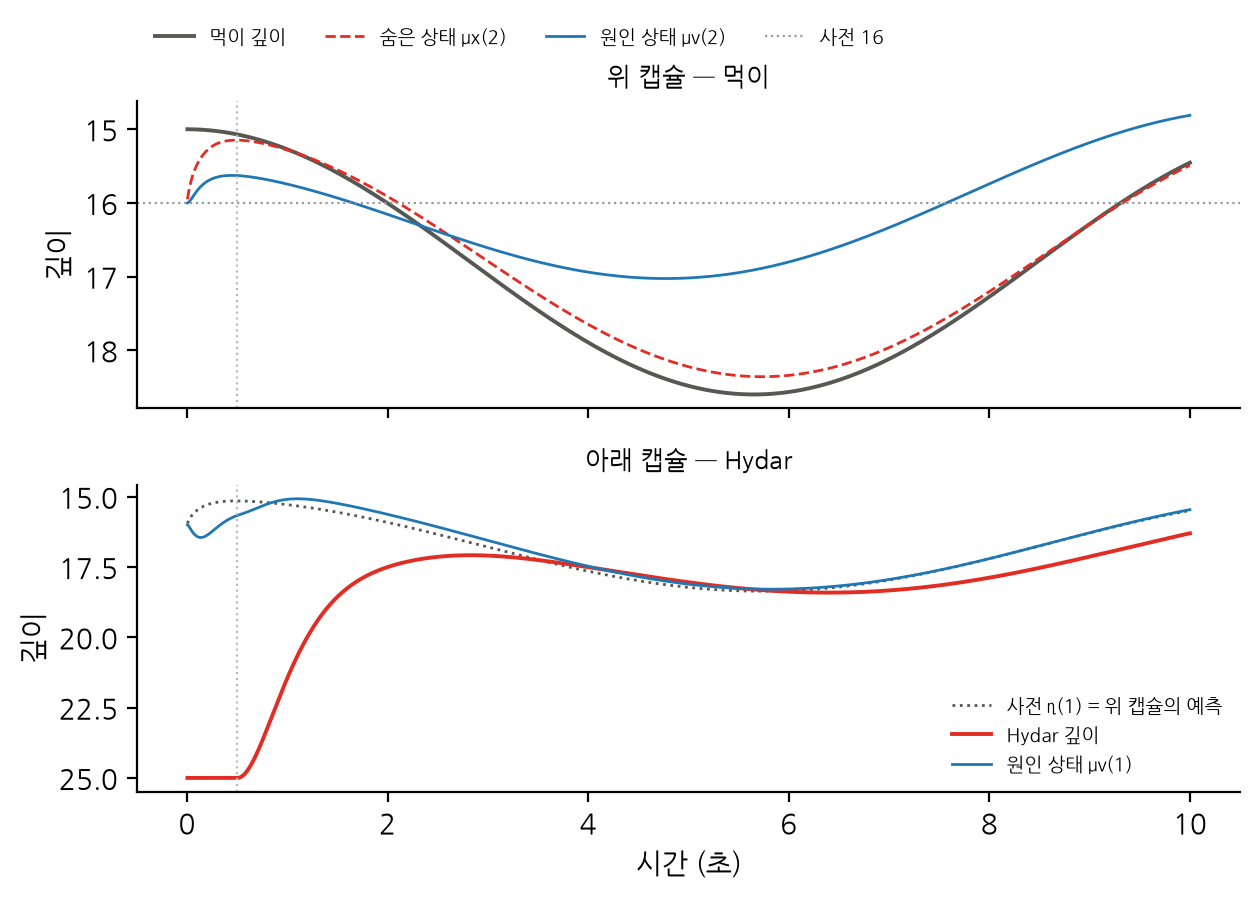

In [6]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.6))
ax[0].plot(r["t"][1:], r["food"][1:], color="#575753", lw=1.4, label="먹이 깊이")
ax[0].plot(r["t"][1:], r["mx2"][1:], color="#E32C24", lw=1.0, ls="--", label="숨은 상태 μx(2)")
ax[0].plot(r["t"][1:], r["mv2"][1:], color="#1f77b4", lw=1.0, label="원인 상태 μv(2)")
ax[0].axhline(16, color="#999999", lw=0.8, ls=":", label="사전 16")
ax[0].set_title("위 캡슐 — 먹이", fontsize=9); ax[0].set_ylabel("깊이")
ax[0].legend(frameon=False, fontsize=7, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.12))
ax[1].plot(r["t"][1:], r["eta"][1:], color="#575753", lw=1.0, ls=":", label="사전 η(1) = 위 캡슐의 예측")
ax[1].plot(r["t"][1:], r["x"][1:], color="#E32C24", lw=1.4, label="Hydar 깊이")
ax[1].plot(r["t"][1:], r["mv1"][1:], color="#1f77b4", lw=1.0, label="원인 상태 μv(1)")
ax[1].set_title("아래 캡슐 — Hydar", fontsize=9); ax[1].set_ylabel("깊이"); ax[1].set_xlabel("시간 (초)")
ax[1].legend(frameon=False, fontsize=7, loc="lower right")
for a_ in ax:
    a_.invert_yaxis(); a_.axvline(0.5, color="#BBBBBB", lw=0.8, ls=":")
fig.tight_layout(); plt.show()

## 4. 위계 없이 고정 사전만 쓰면

같은 아래 캡슐에 위 캡슐 대신 고정된 사전 16 을 준다.

In [7]:
r_fix = run_hier(hierarchy=False, fixed_prior=16.0)
s = r_fix["t"] > 2
print(f"고정 사전 16: Hydar 깊이 − 먹이 RMSE {np.sqrt(np.mean((r_fix['x'][s] - r_fix['food'][s])**2)):.3f},  "
      f"Hydar − 16 RMSE {np.sqrt(np.mean((r_fix['x'][s] - 16)**2)):.3f}")
s = r["t"] > 2
print(f"위계      : Hydar 깊이 − 먹이 RMSE {np.sqrt(np.mean((r['x'][s] - r['food'][s])**2)):.3f}")

고정 사전 16: Hydar 깊이 − 먹이 RMSE 1.543,  Hydar − 16 RMSE 0.540
위계      : Hydar 깊이 − 먹이 RMSE 0.562


## 5. 위 캡슐의 정밀도

위 캡슐의 사전 분산 σv(2)² 와 감각 분산 σy(2)² 를 바꾼다. 감각 분산이 클수록 위 캡슐은 먹이를 보는 눈을 덜 믿는다. 위 캡슐의 숨은 상태가 먹이를 얼마나 따르는지와 Hydar 가 어디를 따라가는지 본다. 먹이가 두 배 빨리 움직이는 경우도 함께 본다.

In [8]:
print("위 캡슐 σy²  σv²    먹이 속도  μx(2)−먹이 RMSE  μv(2)−16 평균  Hydar−먹이 RMSE  Hydar−16 RMSE   지연")
for s2y, s2v, sp in [(0.1, 10.0, 1.0), (0.1, 0.01, 1.0), (1.0, 1.0, 1.0), (10.0, 1.0, 1.0), (100.0, 1.0, 1.0), (0.1, 1.0, 2.0)]:
    rr = run_hier(s2_y_top=s2y, s2_v_top=s2v, food_speed=sp)
    s = rr["t"] > 2
    rm = lambda a, b: np.sqrt(np.mean((a[s] - b[s])**2))
    print(f"{s2y:7.1f}   {s2v:5.2f}    {sp:4.1f}        {rm(rr['mx2'], rr['food']):7.3f}       {np.mean(rr['mv2'][s] - 16):+7.3f}       "
          f"{rm(rr['x'], rr['food']):7.3f}        {np.sqrt(np.mean((rr['x'][s] - 16)**2)):7.3f}     {lag_of(rr['food'], rr['x'], rr['t']):.2f}s")

위 캡슐 σy²  σv²    먹이 속도  μx(2)−먹이 RMSE  μv(2)−16 평균  Hydar−먹이 RMSE  Hydar−16 RMSE   지연


    0.1   10.00     1.0          0.117        +1.006         0.562          1.806     0.56s
    0.1    0.01     1.0          0.264        +0.006         0.622          1.733     0.71s


    1.0    1.00     1.0          0.942        +0.022         0.906          1.040     0.79s


   10.0    1.00     1.0          1.590        +0.005         1.433          0.575     0.00s
  100.0    1.00     1.0          1.703        +0.001         1.532          0.542     0.00s


    0.1    1.00     2.0          0.227        +0.189         0.884          1.732     0.76s


## 결론

- 위 캡슐은 먹이의 깊이를 추론하고, 그 감각 예측이 아래 캡슐의 사전이 된다. 아래 캡슐은 그 사전을 따라 행동해 Hydar 를 먹이 쪽으로 데려간다.
- 고정 사전이면 Hydar 는 16 에 머물고, 위계가 있으면 움직이는 먹이를 따라간다.
- 위 캡슐의 사전 정밀도가 높으면 위 캡슐의 믿음이 사전 쪽에 붙어, Hydar 가 먹이 대신 사전을 따라간다.
- 먹이가 빨라지면 위계의 사슬을 거치는 동안 지연이 쌓인다.